# The `selafin` driver — reading real TELEMAC files

**What the driver does.** **Selafin** (also called Serafin, `.slf`) is the binary result and geometry format of
**TELEMAC**, the open-source free-surface hydrodynamics suite used for rivers, estuaries and coasts. A file holds
a 2D mesh and node-located results over time, in Fortran unformatted records whose byte order the file never
declares. The `selafin` driver reads it into a pyramids `MeshDataset`.

**Why a real file matters here.** Every other Selafin test in this package writes its own fixture and reads it
back, which cannot catch a layout the reader and writer get wrong in the same way. Two details were settled only
by opening files that other software wrote:

- the `IKLE` connectivity block is stored **row-major** (one element's node ids contiguous);
- `IPOBO`, the boundary-node numbering, is populated by BlueKenue even when the header's boundary count says
  zero — so it has to be read from its own record, never inferred from `IPARAM[7]`.

**The samples.** Two independent writers, which is the point:

| File | Source | Licence | What it is |
|---|---|---|---|
| `r2d_tidal_flats.slf` | [oceanmodeling/xarray-selafin](https://github.com/oceanmodeling/xarray-selafin) | GPL-3.0 | TELEMAC 2D output — a sloped flume, 17 time steps, 5 variables |
| `qgismesh.slf` | [hydro-informatics/telemac](https://github.com/hydro-informatics/telemac) | BSD-3-Clause | geometry written by **BlueKenue/QGIS**, in projected UTM coordinates |
| `r3d_bump.slf` | oceanmodeling/xarray-selafin | GPL-3.0 | a genuine layered 3D file (`NDP=6` prisms, 5 planes) — the driver refuses it |
| `r3d_bump_extracted_bottom_layer.slf` | oceanmodeling/xarray-selafin | GPL-3.0 | one layer extracted from a 3D run — a 2D mesh that *looks* 3D in the header |


## Getting the data

These four files are also committed, under `tests/data/selafin/`, so the driver's own tests run offline. This
notebook fetches its own copy anyway, into `examples/data/`, for two reasons: an example must be runnable on its
own from a fresh clone of the docs, and notebooks in this repository read `examples/data/`, never the test
fixtures. The download is therefore a convenience, not the only copy — if you have the repository you already
have these bytes.

Unlike the other notebooks in this folder, the samples come straight from the two public GitHub repositories
above rather than from the project's Drive folder: both are permanently hosted, openly licensed and directly
addressable, so there is nothing to mirror. Pinned to a commit, staged through a temporary file, standard library
only.

In [1]:
from pathlib import Path
import os, tempfile, urllib.request

DATA = Path("../../../examples/data/real-data") / "selafin"
# Pinned to a commit, not a branch: a sample that changes under us would silently change
# every number below. Downloaded to a temporary file and moved into place, so an
# interrupted fetch cannot leave a half-file that later runs mistake for a cached one.
XS = "https://raw.githubusercontent.com/oceanmodeling/xarray-selafin/168855a47c41beb609c201995ba70ce27e6fb9d6/tests/data/"
HI = "https://raw.githubusercontent.com/hydro-informatics/telemac/d2cbc4454e2a895c85023bd2050a00ecb4d88c00/"
SAMPLES = {
    "r2d_tidal_flats.slf": XS + "r2d_tidal_flats.slf",
    "r3d_bump.slf": XS + "r3d_bump.slf",
    "r3d_bump_extracted_bottom_layer.slf": XS + "r3d_bump_extracted_bottom_layer.slf",
    "qgismesh.slf": HI + "bk-slf/qgismesh.slf",
}

DATA.mkdir(parents=True, exist_ok=True)
for name, url in SAMPLES.items():
    target = DATA / name
    if target.exists():
        print(f"present: {name} ({target.stat().st_size / 1024:.0f} KB)")
        continue
    print(f"downloading {name} ...")
    handle, staged = tempfile.mkstemp(dir=DATA, suffix=".part")
    os.close(handle)
    try:
        urllib.request.urlretrieve(url, staged)
        os.replace(staged, target)
    except BaseException:
        os.unlink(staged)        # no half-file left behind for the next run to find
        raise
    print(f"  saved {target.stat().st_size / 1024:.0f} KB")

present: r2d_tidal_flats.slf (236 KB)
downloading r3d_bump.slf ...


  saved 757 KB
present: r3d_bump_extracted_bottom_layer.slf (133 KB)
present: qgismesh.slf (494 KB)


## Opening a TELEMAC result file

`MeshDataset.read_file` dispatches on the driver name. Paths are `pathlib.Path` objects — pyramids takes them
directly.

In [2]:
from pyramids.netcdf.ugrid import MeshDataset

ds = MeshDataset.read_file(DATA / "r2d_tidal_flats.slf", driver="selafin")
ds

MeshDataset(mesh='mesh2d', n_node=648, n_face=1030, n_edge=0, variables=['VELOCITY U', 'VELOCITY V', 'WATER DEPTH', 'FREE SURFACE', 'BOTTOM', 'boundary_node_number'])

cleopatra switches matplotlib to a headless backend on that first read, so hand it its own chooser once and
figures will embed in the cells below.

In [3]:
from cleopatra.config import Config

Config.set_matplotlib_backend()

'inline'

## What the file declares

The mesh is small — a flume 50 km long and 1 km wide, discretised into triangles. Note `crs`: Selafin carries no
coordinate reference system at all, and the driver never guesses one from the magnitude of the coordinates.

In [4]:
print("nodes  :", ds.n_node)
print("faces  :", ds.n_face)
print("crs    :", ds.crs)
print("bounds :", ds.bounds)
print("vars   :", ds.variable_names)

nodes  : 648
faces  : 1030
crs    : None
bounds : (-25000.0, -500.0, 25000.0, 500.0)
vars   : ['VELOCITY U', 'VELOCITY V', 'WATER DEPTH', 'FREE SURFACE', 'BOTTOM', 'boundary_node_number']


Five of those variables are results; `boundary_node_number` is not — it is the file's own boundary numbering,
which we come back to below.

The time axis is in **seconds**, counting from the file's start date.

In [5]:
import numpy as np

times = np.asarray(ds.time_values)
print("steps    :", len(times))
print("first    :", times[:4])
print("step size:", np.unique(np.diff(times)), "s")

steps    : 17
first    : [    0. 10000. 20000. 30000.]
step size: [10000.] s


## The header metadata

Three header fields are worth more than their size suggests, and all three reach the dataset:

- **`title`** — the run's own name for itself, as TELEMAC wrote it.
- **`start_date`** — the instant the time axis is measured from. Without it, `[0, 10000, 20000, ...]` seconds has
  nothing to anchor it to.
- **`n_boundary_nodes`** — how many nodes carry a boundary number.

In [6]:
ds.global_attributes

{'source': 'TELEMAC Selafin',
 'n_timesteps': 17,
 'title': 'Sloped flume Rouse profile test',
 'start_date': '1900-01-01T00:00:00',
 'n_boundary_nodes': 264}

So the fourth time step is not "30000" but a real instant:

In [7]:
start = ds.global_attributes["start_date"]
print(f"start of the run : {start}")
print(f"step 4 is at     : {start} + {times[3]:.0f} s = {times[3] / 3600:.1f} h in")

start of the run : 1900-01-01T00:00:00
step 4 is at     : 1900-01-01T00:00:00 + 30000 s = 8.3 h in


## The mesh itself

Everything derived from a topology already in hand — areas, centroids, edges — belongs to pyramids, not to this
driver. The driver's job ends once the arrays are built.

In [8]:
m = ds.mesh
cx, cy = m.face_centroids
print("node_x            :", m.node_x.shape)
print("connectivity      :", m.face_node_connectivity.data.shape, "(triangles)")
print("original base     :", m.face_node_connectivity.original_start_index, "(IKLE is 1-based)")
print("face areas (first):", np.round(m.face_areas[:3], 1))
print("total area        :", f"{m.face_areas.sum():,.0f} m^2")

node_x            : (648,)
connectivity      : (1030, 3) (triangles)
original base     : 1 (IKLE is 1-based)
face areas (first): [60566.3 46411.  45412.8]
total area        : 50,000,000 m^2


That total is the sanity check on the connectivity: the flume is 50,000 m x 1,000 m, so the face areas have to
sum to its footprint. Rather than claim they do, take the difference — and compare against reading `IKLE` the
other way round, which is the one detail the format specification could not settle for us.

In [9]:
footprint = 50_000.0 * 1_000.0
conn = m.face_node_connectivity.data
x, y = m.node_x[conn], m.node_y[conn]
row_major = 0.5 * (
    x[:, 0] * (y[:, 1] - y[:, 2])
    + x[:, 1] * (y[:, 2] - y[:, 0])
    + x[:, 2] * (y[:, 0] - y[:, 1])
)
# The same bytes read column-major: what a transposed reader would have produced.
transposed_conn = conn.reshape(-1).reshape(conn.shape[1], conn.shape[0]).T
xt, yt = m.node_x[transposed_conn], m.node_y[transposed_conn]
col_major = 0.5 * (
    xt[:, 0] * (yt[:, 1] - yt[:, 2])
    + xt[:, 1] * (yt[:, 2] - yt[:, 0])
    + xt[:, 2] * (yt[:, 0] - yt[:, 1])
)

print(f"footprint                 : {footprint:,.1f} m^2")
print(f"row-major    sum|area|    : {np.abs(row_major).sum():,.1f} m^2")
print(f"             residual     : {abs(np.abs(row_major).sum() - footprint):.6f} m^2")
print(f"             inverted     : {int((row_major < 0).sum())} of {row_major.size}")
print(f"column-major sum|area|    : {np.abs(col_major).sum():,.1f} m^2"
      f"  ({np.abs(col_major).sum() / footprint:.0f}x the domain)")
print(f"             inverted     : {int((col_major < 0).sum())} of {col_major.size}")

footprint                 : 50,000,000.0 m^2
row-major    sum|area|    : 50,000,000.0 m^2
             residual     : 0.000000 m^2
             inverted     : 0 of 1030
column-major sum|area|    : 4,450,837,336.9 m^2  (89x the domain)
             inverted     : 537 of 1030


The residual is zero to the last decimal and no triangle is inverted, so the elements tessellate the domain
once. Read column-major they cover it many times over with hundreds of triangles wound backwards — which is why
row-major is not a guess.

## Plotting the mesh and a result

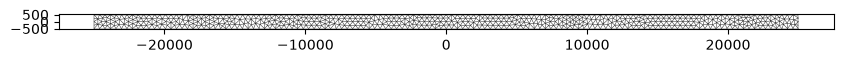

In [10]:
g = ds.plot_outline()

`WATER DEPTH` at the last time step. The flume is sloped, so the water deepens towards one end.

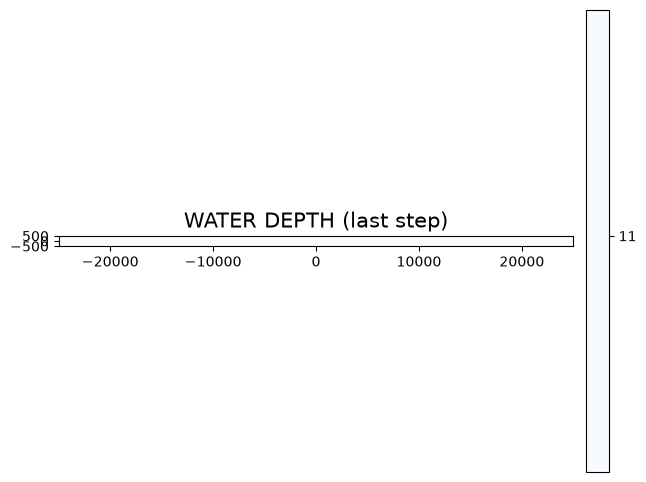

In [11]:
g = ds.plot("WATER DEPTH", cmap="Blues", colorbar=True, title="WATER DEPTH (last step)")

A variable is a `(time, node)` array, so a time series at one node is an ordinary slice. Take the deepest node
and watch it fill.

variable shape: (17, 648) -> node 4


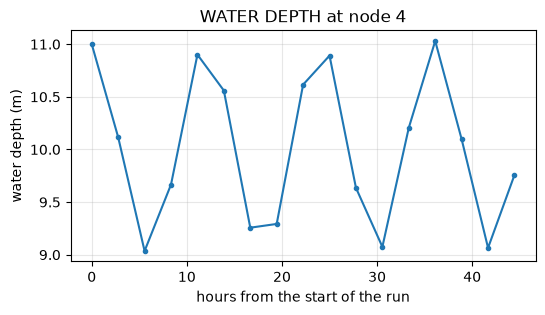

In [12]:
import matplotlib.pyplot as plt

depth = np.asarray(ds.get("WATER DEPTH").data)
node = int(depth[-1].argmax())
print("variable shape:", depth.shape, "-> node", node)

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(times / 3600, depth[:, node], marker="o", ms=3)
ax.set_xlabel("hours from the start of the run")
ax.set_ylabel("water depth (m)")
ax.set_title(f"WATER DEPTH at node {node}")
ax.grid(alpha=0.3)

The depth climbs for the first few hours and then settles — the run reaching a steady state, which is what this
validation case is for.

## The boundary numbering (`IPOBO`)

TELEMAC needs to know which nodes are on the boundary, and in what order, to attach boundary conditions. That
numbering is in the file as the `IPOBO` record, and it is **not** recoverable from the topology: the set of
boundary nodes is, but their ordering is not. So the driver carries it through as a node variable, and writes it
back when you write the file.

In [13]:
boundary = np.asarray(ds.get("boundary_node_number").data)
on_boundary = boundary != 0
print("nodes           :", boundary.size)
print("boundary nodes  :", int(on_boundary.sum()))
print("numbered 1 ..   :", int(boundary.max()))

nodes           : 648
boundary nodes  : 264
numbered 1 ..   : 264


Plotting them shows what they are: the outline of the domain, in order.

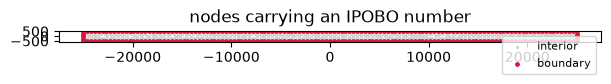

In [14]:
fig, ax = plt.subplots(figsize=(7, 2.4))
ax.scatter(m.node_x[~on_boundary], m.node_y[~on_boundary], s=2, c="lightgrey", label="interior")
ax.scatter(m.node_x[on_boundary], m.node_y[on_boundary], s=6, c="crimson", label="boundary")
ax.set_aspect("equal")
ax.legend(loc="upper right", fontsize=8)
ax.set_title("nodes carrying an IPOBO number");

## Writing a file back

`to_file` emits the same record layout, and restores the header rather than stamping the file with the library's
own name: the title, the date record and `IPOBO` all survive. That matters because a Selafin file with an
all-zero `IPOBO` is geometry only — TELEMAC cannot use it as the mesh for a run with boundary conditions.

In [15]:
import tempfile

with tempfile.TemporaryDirectory() as tmp:
    out = Path(tmp) / "round_trip.slf"
    ds.to_file(out, driver="selafin")
    again = MeshDataset.read_file(out, driver="selafin")

    print("title      :", again.global_attributes["title"])
    print("start_date :", again.global_attributes["start_date"])
    print("boundary   :", again.global_attributes["n_boundary_nodes"], "nodes")
    print("nodes/faces:", again.n_node, again.n_face)
    print("depth equal:", np.allclose(depth, np.asarray(again.get("WATER DEPTH").data)))

title      : Sloped flume Rouse profile test
start_date : 1900-01-01T00:00:00
boundary   : 264 nodes
nodes/faces: 648 1030
depth equal: True


## A second writer: BlueKenue geometry

`qgismesh.slf` was not written by TELEMAC but by **BlueKenue**, the mesh editor many TELEMAC users build their
geometry in. It is a geometry file: one variable (`BOTTOM`, the bed elevation), one time step, and real projected
coordinates rather than a tidy unit square.

Reading a file from a different writer is the only way to be sure the layout was understood rather than merely
mirrored.

In [16]:
geo = MeshDataset.read_file(DATA / "qgismesh.slf", driver="selafin")
print("title  :", geo.global_attributes["title"])
print("nodes  :", geo.n_node, " faces:", geo.n_face)
print("vars   :", geo.variable_names)
print("bounds :", tuple(round(b, 1) for b in geo.bounds))
print("steps  :", len(np.asarray(geo.time_values)))

title  : new Selafin
nodes  : 12814  faces: 25007
vars   : ['BOTTOM', 'boundary_node_number']
bounds : (315120.2, 5345116.5, 316911.6, 5346307.5)
steps  : 1


Those coordinates are metres in a UTM zone — around 315,000 E and 5,346,000 N — so this is a real river
reach, roughly 1.8 km by 1.2 km. The file still declares no CRS, so `geo.crs` is `None` and you must know the projection from
elsewhere.

This file is also the one that shows why `IPOBO` cannot be taken from the header: BlueKenue leaves the
boundary-point count at zero while writing a fully populated boundary record.

In [17]:
import struct


def iparam_of(path):
    """Read the 10-int IPARAM array out of a big-endian Selafin header (stdlib only).

    Hard-codes ">" because every sample here is big-endian, which is what TELEMAC and
    BlueKenue write. The driver does not assume it: it detects the byte order from the
    first record's length word. This is the short version, for one known file.
    """
    with open(path, "rb") as fh:
        def record():
            size = struct.unpack(">i", fh.read(4))[0]
            payload = fh.read(size)
            fh.read(4)                                   # the trailing length word
            return payload
        record()                                         # title
        nbv = struct.unpack(">2i", record())
        for _ in range(sum(nbv)):
            record()                                     # one record per variable name
        return struct.unpack(">10i", record())


geo_boundary = np.asarray(geo.get("boundary_node_number").data)
print("crs                      :", geo.crs)
print("IPARAM[7] (header count) :", iparam_of(DATA / "qgismesh.slf")[7])
print("non-zero IPOBO entries   :", int(np.count_nonzero(geo_boundary)))

crs                      : None
IPARAM[7] (header count) : 0
non-zero IPOBO entries   : 619


Plotted, the bed elevation shows the channel it was meshed for — the detail the mesh was refined around.

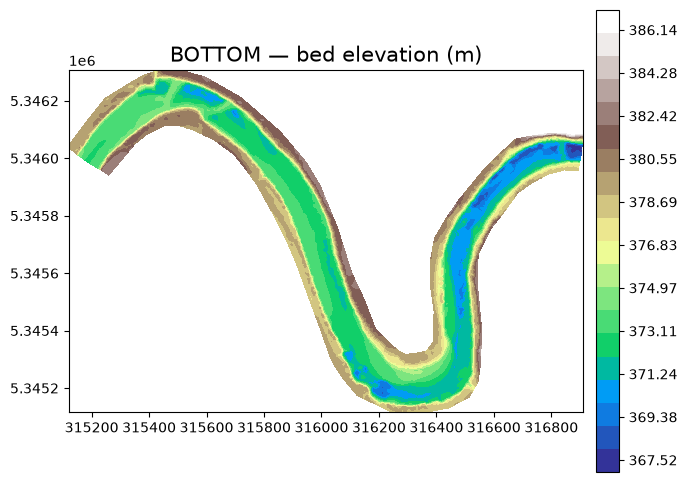

In [18]:
g = geo.plot("BOTTOM", cmap="terrain", colorbar=True, title="BOTTOM — bed elevation (m)")

## What the driver refuses, and what it does not

A Selafin file can also be **3D**: TELEMAC-3D stacks the 2D mesh into layers and stores 6-node prisms. There is
no layered mesh model in pyramids to put that in, and slicing one plane out of it would be a mesh operation
rather than a file-format one, so the driver refuses such a file instead of returning every plane's nodes under
6-node "faces".

In [19]:
from pyramids.netcdf.ugrid import UnsupportedMeshFormatError

try:
    MeshDataset.read_file(DATA / "r3d_bump.slf", driver="selafin")
except UnsupportedMeshFormatError as error:
    # The dispatcher wraps the driver's own error; __cause__ is that error, so printing it
    # gives the driver's explanation once rather than quoted inside the wrapper.
    print("refused:", error.__cause__)

refused: '..\\..\\..\\examples\\data\\real-data\\selafin\\r3d_bump.slf' is a layered 3D Selafin file (NDP=6 prisms over 5 plane(s)); only 2D meshes are read. A 3D read needs the layered mesh model pyramids does not have yet, and extracting a single plane is a mesh operation that belongs upstream rather than in a format driver.


The interesting part is what decides it. The header's plane count (`IPARAM[6]`) looks like the obvious test, and
it is the wrong one: TELEMAC's own single-layer extraction **copies the parent run's plane count** into a file
whose elements are plain triangles. Keying on the count refused a perfectly readable 2D mesh.

`NDP`, the element width, is what actually distinguishes the two — 3 or 4 nodes is a surface mesh, 6 is a prism.
So this file, with a plane count of 5 and triangles, reads:

In [20]:
layer = MeshDataset.read_file(DATA / "r3d_bump_extracted_bottom_layer.slf", driver="selafin")
print("title        :", layer.global_attributes["title"])
print("nodes/faces  :", layer.n_node, layer.n_face)
print("element width :", layer.mesh.face_node_connectivity.data.shape[1], "(triangles)")
print("vars         :", [v for v in layer.variable_names if v != "boundary_node_number"])
print("total area   :", f"{layer.mesh.face_areas.sum():.2f} m^2")
print("bbox area    :", f"{(layer.bounds[2] - layer.bounds[0]) * (layer.bounds[3] - layer.bounds[1]):.2f} m^2")

title        : TELEMAC 3D : NON HYDROSTATIC HYDRAULIC JUMP
nodes/faces  : 1452 2620
element width : 3 (triangles)
vars         : ['ELEVATION Z', 'VELOCITY U', 'VELOCITY V', 'VELOCITY W', 'DYNAMIC PRESSURE']
total area   : 41.92 m^2
bbox area    : 41.92 m^2


And it carries its results, so the extracted layer plots like any other 2D file — streamwise velocity over
the bump that gives the case its name.

The two agree to the last digit, which is the same tessellation check as for the 2D file — and a reminder to
measure rather than assume: the case is known as a 21.2 x 2.0 flume, but the mesh starts at x = 0.24, so its
extent is 20.96 x 2.0 = 41.92 m², not 42.40. Comparing against the nominal figure would have shown a 1 %
"discrepancy" that is not one.


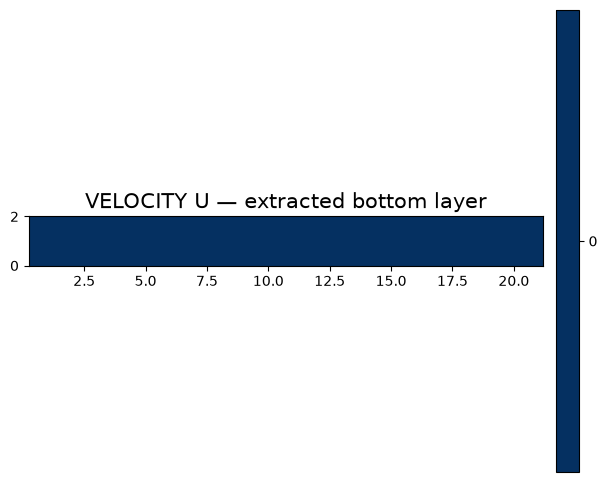

In [21]:
g = layer.plot("VELOCITY U", cmap="RdBu_r", colorbar=True, title="VELOCITY U — extracted bottom layer")

`can_open` agrees with all of this, which matters because driver auto-detection trusts it: a file the read
refuses is not claimed in the first place.

In [22]:
from pyramids_mesh.drivers.coastal_ocean.telemac import SelafinDriver

driver = SelafinDriver()
# str() here on purpose: the read/write APIs take a Path, but can_open() is a driver-level
# sniff that works on the raw string (it matches the suffix with str.lower()).
for name in SAMPLES:
    print(f"{name:40s} can_open={driver.can_open(str(DATA / name))}")

r2d_tidal_flats.slf                      can_open=True
r3d_bump.slf                             can_open=False
r3d_bump_extracted_bottom_layer.slf      can_open=True
qgismesh.slf                             can_open=True


## Summary

- The `selafin` driver reads TELEMAC 2D geometry and results, from TELEMAC's own output and from BlueKenue alike.
- `IKLE` is row-major — checked against both writers, not assumed from the specification.
- The title, the start date and the `IPOBO` boundary numbering survive a read **and** a write, so a file written
  back is still usable by the model.
- Layered 3D files are refused on their element width, not on the header's plane count, so a single layer
  extracted from a 3D run reads as the 2D mesh it is.
- There is no CRS in the format. `crs` is always `None`, and you supply the projection yourself.
